# Step 1. Importing libraries and dataset; basic preprocessing

In [ ]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import QuantileTransformer
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from scipy.stats import zscore
from sklearn.metrics import silhouette_score
import umap
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import DBSCAN
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import kneighbors_graph
from scipy.sparse import csr_matrix
import hdbscan
import pickle

# import the data
df = pd.read_csv('star-galaxy-quasar.csv', skiprows=1)

df = pd.read_csv('star-galaxy-quasar.csv', comment='#', skiprows=1)
labels = df['class'].copy()
df = df.drop(columns=['objid', 'class', 'ra', 'dec'])

# Replace missing data with the median
df['z'] = df['z'].replace(-9999, np.nan)
df['z'] = df['z'].fillna(df['z'].median())

# Transform variables
def engineer(df):
    f = pd.DataFrame()
    f['u_g'] = df['u'] - df['g']
    f['g_r'] = df['g'] - df['r']
    f['r_i'] = df['r'] - df['i']
    f['i_z'] = df['i'] - df['z']
    f['redshift'] = df['redshift']
    return f

X_raw = df[['u','g','r','i','z','redshift']]
X_eng = engineer(df)

# Remove outliers from X_eng
z_scores = np.abs(zscore(X_eng))
threshold = 3
mask = (z_scores < threshold).all(axis=1)
X_eng = X_eng[mask]
X_raw = X_raw[mask]
labels = labels[mask].reset_index(drop=True)

# Normalize data
X_raw_s = StandardScaler().fit_transform(X_raw)
X_eng_s = StandardScaler().fit_transform(X_eng)


# Step 2. Transform data using PCA and UMAP, plot resulting transformations

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


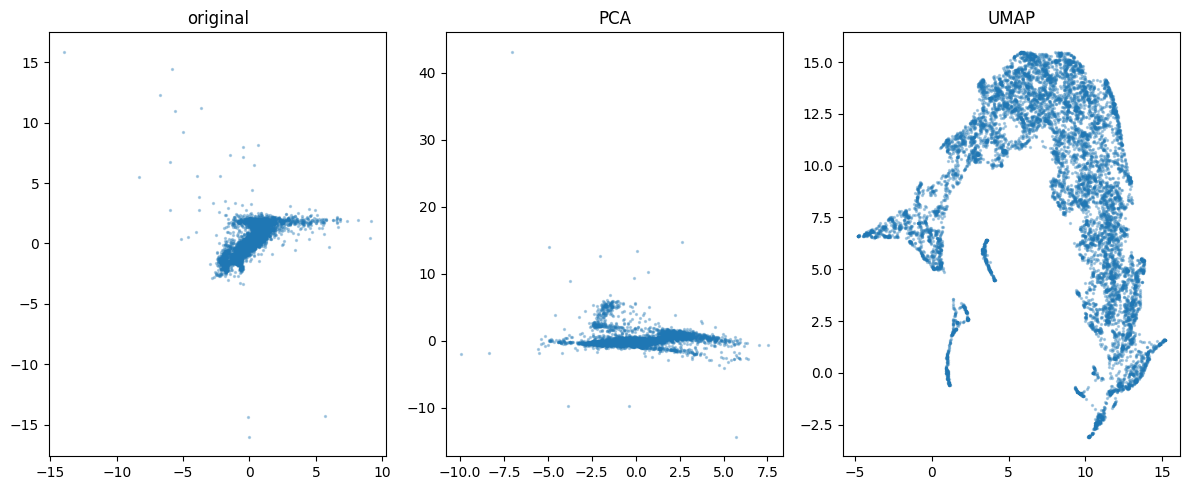

In [ ]:
# PCA
pca = PCA(n_components=2).fit_transform(X_eng_s)

# UMAP
embedding = umap.UMAP(n_components=2, random_state= 42).fit_transform(X_eng_s)

# plot the original graph vs PCA vs UMAP
# note that the original is a projection because of high dimensionality
# however, changing the axes plotted should not substantially alter the
# nature of the graph
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

for ax, coords, title in zip(axes, [X_eng_s, pca, embedding], ['original', 'PCA', 'UMAP']):
    ax.scatter(coords[:, 0], coords[:, 1], s=2, alpha=0.3)
    ax.set_title(title)

plt.tight_layout()
plt.show()

# Step 3. Try different clustering algorithms on the transformed data

In [ ]:
# METHOD 1: K-means++
model_km = [
    KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=42).fit(embedding)
    for k in range(2, 8)
]
pred_km = [model.predict(embedding) for model in model_km]


# METHOD 2: GMM
model_gmm = [
    GaussianMixture(n_components=n, random_state=42, n_init=5).fit(embedding)
    for n in range(2, 8)
]
pred_gmm = [model.predict(embedding) for model in model_gmm]


# METHOD 3: Agglomerative Clustering
model_ac = [
    AgglomerativeClustering(n_clusters=n, linkage="single").fit(embedding)
    for n in range(2, 8)
]
pred_ac = [model.labels_ for model in model_ac]


# METHOD 4: HDBSCAN
model_hdb = hdbscan.HDBSCAN(min_cluster_size=50).fit(embedding)
pred_hdb = model_hdb.labels_

# Step 4. Model evaluation and selection



In [ ]:
# evaluate each model using a conductance score. lower score is better.
# the model with the lowest conductance should be selected to be our final model


def cluster_conductance(X, labels, n_neighbors=10):
    """
    Compute average conductance over clusters using a k-NN graph.

    Lower conductance is better:
    - low = few edges leaving cluster relative to its volume
    - high = poorly separated cluster
    """
    A = kneighbors_graph(X, n_neighbors=n_neighbors, mode="connectivity", include_self=False)
    A = 0.5 * (A + A.T)  # symmetrize
    A = csr_matrix(A)

    unique_labels = np.unique(labels)
    conductances = []

    for c in unique_labels:
        inside = np.where(labels == c)[0]
        outside = np.where(labels != c)[0]

        if len(inside) == 0 or len(outside) == 0:
            continue

        cut = A[inside][:, outside].sum()
        vol_inside = A[inside].sum()
        vol_outside = A[outside].sum()

        denom = min(vol_inside, vol_outside)
        if denom > 0:
            conductances.append(cut / denom)

    return np.mean(conductances) if conductances else np.nan

for name, preds, in [('K-means', pred_km), ('GMM', pred_gmm), ('Agglo', pred_ac)]:
    for k, pred in enumerate(preds, start=2):
        print(f"{name} n={k} | Conductance: {cluster_conductance(embedding, pred):.4f}")

for name, pred in [('HDBSCAN', pred_hdb)]:
    cond = cluster_conductance(embedding, pred, n_neighbors = 10)
    print(f"Average conductance ({name}): {cond}")

#For agglomerative clustering, we choose k = 3 because it achieves simultaneous best conductance score and agrees with the visual.

K-means n=2 | Conductance: 0.0052
K-means n=3 | Conductance: 0.0032
K-means n=4 | Conductance: 0.0057
K-means n=5 | Conductance: 0.0087
K-means n=6 | Conductance: 0.0110
K-means n=7 | Conductance: 0.0102
GMM n=2 | Conductance: 0.0066
GMM n=3 | Conductance: 0.0041
GMM n=4 | Conductance: 0.0052
GMM n=5 | Conductance: 0.0061
GMM n=6 | Conductance: 0.0080
GMM n=7 | Conductance: 0.0117
Agglo n=2 | Conductance: 0.0000
Agglo n=3 | Conductance: 0.0000
Agglo n=4 | Conductance: 0.0000
Agglo n=5 | Conductance: 0.0002
Agglo n=6 | Conductance: 0.1669
Agglo n=7 | Conductance: 0.2411
Average conductance (HDBSCAN): 0.0


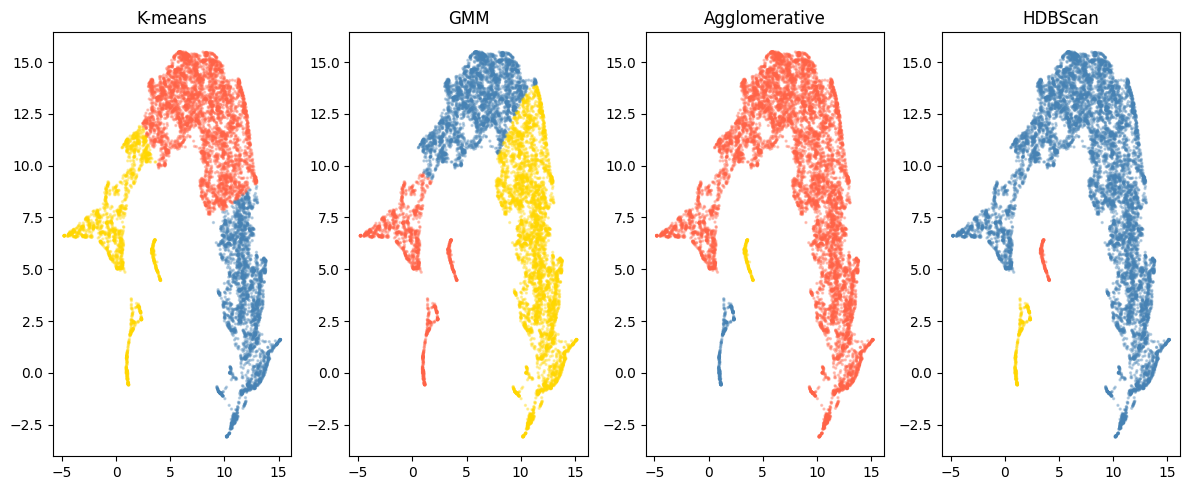

In [ ]:
# compare the graphs for K-means, GMM and agglomerative method. All for k = 3

color_map = {0: 'tomato', 1: 'gold', 2: 'steelblue'}

colors1 = pd.Series(pred_km[1]).map(color_map)
colors2 = pd.Series(pred_gmm[1]).map(color_map)
colors3 = pd.Series(pred_ac[1]).map(color_map)
colors4 = pd.Series(pred_hdb).map(color_map)

fig, axes = plt.subplots(1, 4, figsize=(12, 5))
titles = ['K-means', 'GMM', 'Agglomerative', 'HDBScan']
colorss = [colors1, colors2, colors3, colors4]
for ax, title, colors in zip(axes, titles, colorss):
    coords = embedding
    ax.scatter(coords[:, 0], coords[:, 1], c=colors, s=2, alpha=0.3)
    ax.set_title(title)

plt.tight_layout()
plt.show()

# Step 5. Select final model and test against true labels

Based on performance in model evaluation and selection step, we choose agglomerative clustering as our final model, and evaluate how well it matches the true labels of the data, using both ARI scores and a graphical method. We choose agglomerative clustering as we do not have tune hyperparameters as in HDBScan. We cannot know a priori how many should be in each cluster.

ARI: 0.4534731961181279


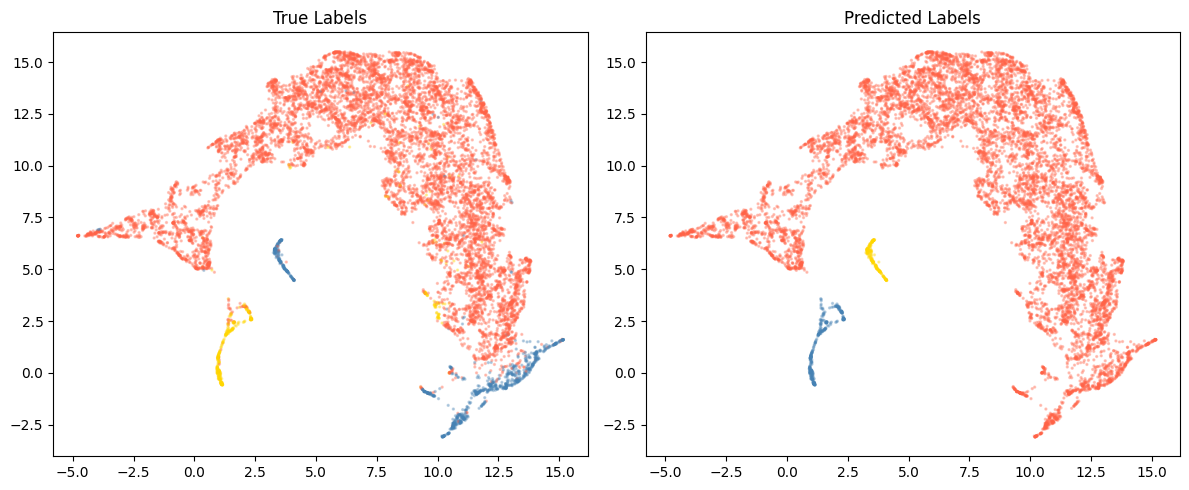

In [ ]:
# evaluate the final model using ARI scores
final_model = model_ac[1]
final_labels = pred_ac[1]
ari = adjusted_rand_score(final_labels, labels)
print(f"ARI: {ari}")

# compare the clusters of our final model against the true labels
color_map_1 = {'STAR': 'steelblue', 'GALAXY': 'tomato', 'QSO': 'gold'}
color_map_2 = {0: 'tomato', 1: 'gold', 2: 'steelblue'}
colors1 = labels.map(color_map_1)
colors2 = pd.Series(final_labels).map(color_map)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
titles = ['True Labels', 'Predicted Labels']
colorss = [colors1, colors2]
for ax, title, colors in zip(axes, titles, colorss):
    coords = embedding
    ax.scatter(coords[:, 0], coords[:, 1], c=colors, s=2, alpha=0.3)
    ax.set_title(title)

plt.tight_layout()
plt.show()

# Step 6. Save model into pickle file

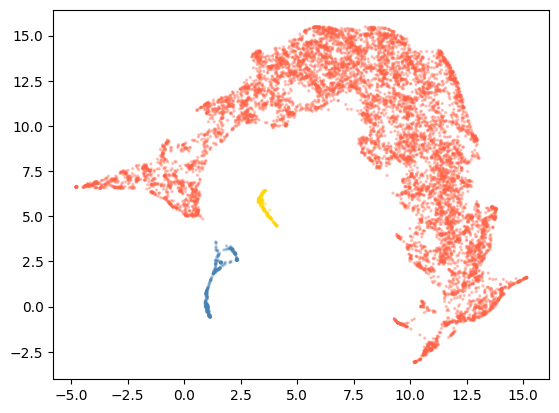

In [ ]:
# creates an object storing the model together with original data and transformed data

model_with_data = {
    'model': final_model,
    'original_data': X_raw,
    'transformed_data': embedding
}


with open('model.pkl', 'wb') as f:
  pickle.dump(model_with_data, f)

# test loading the model
with open('model.pkl', 'rb') as f:
  loaded_model = pickle.load(f)

loaded_labels = loaded_model['model'].labels_
loaded_data = loaded_model['transformed_data']

colors = pd.Series(loaded_labels).map(color_map)
plt.scatter(loaded_data[:, 0], loaded_data[:, 1], c=colors, s=2, alpha=0.3)
plt.show()